<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_5_NLP_and_Clustering/Projects/Instructions/Project.5-NLP/Project_5_Pass_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 5 - Pass 01

# The Goal
1. Pick one person from the list ( Jonathan Hoefler ) and output 10 other people who's overview are "closest" to the reference person in a Natural Language Processing sense
2. Also output the sentiment of the overview of the reference person

# Installs and Imports

In [81]:
%%capture
!python -m textblob.download_corpora

In [82]:
%%capture output
#install Wikipedia API
!pip3 install wikipedia-api

In [83]:
# Import the libraries and modules
import numpy as np
import pandas as pd
from textblob import TextBlob
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import TfidfTransformer

pd.options.display.max_columns = 100

import nltk
# nltk.download('omw-1.4')
# nltk.download('punkt_tab')
# nltk.download('averaged_perceptron_tagger_eng')

import wikipediaapi

## Data Collection/Sources

In [84]:
! curl -s -I https://ddc-datascience.s3.amazonaws.com/Projects/Project.5-NLP/Data/NLP.csv

HTTP/1.1 200 OK
x-amz-id-2: TvJLUVQ7e6wK+v93d3RSxgdTq4xljO4glNCZKX7DImHcr36O7K0nI/B2NyjimRk6uHMu0pacTFeZgpnCb3y1b5fLzDNDi1d+
x-amz-request-id: ZNFJ6G2R35CEZ9B9
Server: AmazonS3
Date: Thu, 26 Nov 2026 15:35:20 GMT
Last-Modified: Mon, 23 Oct 2023 18:30:29 GMT
ETag: "f4f3b3bc07aa7b6dddb6e383fc52ae64-10"
x-amz-server-side-encryption: AES256
Accept-Ranges: bytes
Content-Length: 83886080
Content-Type: text/csv



In [85]:
! curl -s https://ddc-datascience.s3.amazonaws.com/Projects/Project.5-NLP/Data/NLP.csv | head -2

URI,name,text
<http://dbpedia.org/resource/Digby_Morrell>,Digby Morrell,digby morrell born 10 october 1979 is a former australian rules footballer who played with the kangaroos and carlton in the australian football league aflfrom western australia morrell played his early senior football for west perth his 44game senior career for the falcons spanned 19982000 and he was the clubs leading goalkicker in 2000 at the age of 21 morrell was recruited to the australian football league by the kangaroos football club with its third round selection in the 2001 afl rookie draft as a forward he twice kicked five goals during his time with the kangaroos the first was in a losing cause against sydney in 2002 and the other the following season in a drawn game against brisbaneafter the 2003 season morrell was traded along with david teague to the carlton football club in exchange for corey mckernan he played 32 games for the blues before being delisted at the end of 2005 he continued to play victoria

### Load Data

In [86]:
# Define the data's url as 'url'
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.5-NLP/Data/NLP.csv'    # insert url here
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Project.5-NLP/Data/NLP.csv'

In [87]:
# Define the data frame as 'df'
df = pd.read_csv(url, nrows=20)

In [88]:
df.head()

,URI,name,text
0,<http://dbpedia.org/resource/Digby_Morrell>,Digby Morrell,digby morrell born 10 october 1979 is a former...
1,<http://dbpedia.org/resource/Alfred_J._Lewy>,Alfred J. Lewy,alfred j lewy aka sandy lewy graduated from un...
2,<http://dbpedia.org/resource/Harpdog_Brown>,Harpdog Brown,harpdog brown is a singer and harmonica player...
3,<http://dbpedia.org/resource/Franz_Rottensteiner>,Franz Rottensteiner,franz rottensteiner born in waidmannsfeld lowe...
4,<http://dbpedia.org/resource/G-Enka>,G-Enka,henry krvits born 30 december 1974 in tallinn ...


In [89]:
df.tail()

,URI,name,text
15,<http://dbpedia.org/resource/Joerg_Steineck>,Joerg Steineck,joerg steineck is a german filmmaker editor an...
16,<http://dbpedia.org/resource/Andrew_Pinsent>,Andrew Pinsent,fr andrew pinsent born 19 august 1966 is resea...
17,<http://dbpedia.org/resource/Paddy_Dunne_(Gael...,Paddy Dunne (Gaelic footballer),paddy dunne was a gaelic football player from ...
18,<http://dbpedia.org/resource/Alexandros_Mouzas>,Alexandros Mouzas,alexandros mouzas born 1962 is a greek compose...
19,<http://dbpedia.org/resource/John_Angus_Campbell>,John Angus Campbell,john angus campbell born march 10 1942 in port...


In [90]:
df.shape

(20, 3)

In [91]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   URI     20 non-null     object
 1   name    20 non-null     object
 2   text    20 non-null     object
dtypes: object(3)
memory usage: 612.0+ bytes


In [92]:
df[['name', 'text']]

,name,text
0,Digby Morrell,digby morrell born 10 october 1979 is a former...
1,Alfred J. Lewy,alfred j lewy aka sandy lewy graduated from un...
2,Harpdog Brown,harpdog brown is a singer and harmonica player...
3,Franz Rottensteiner,franz rottensteiner born in waidmannsfeld lowe...
4,G-Enka,henry krvits born 30 december 1974 in tallinn ...
5,Sam Henderson,sam henderson born october 18 1969 is an ameri...
6,Aaron LaCrate,aaron lacrate is an american music producer re...
7,Trevor Ferguson,trevor ferguson aka john farrow born 11 novemb...
8,Grant Nelson,grant nelson born 27 april 1971 in london also...
9,Cathy Caruth,cathy caruth born 1955 is frank h t rhodes pro...


In [93]:
df.loc[df['name'] == 'Jonathan Hoefler']

,URI,name,text
12,<http://dbpedia.org/resource/Jonathan_Hoefler>,Jonathan Hoefler,jonathan hoefler born august 22 1970 is an ame...


In [94]:
# Make a list of all the bios
all_bios = list(df['text'])
all_bios[:3]

['digby morrell born 10 october 1979 is a former australian rules footballer who played with the kangaroos and carlton in the australian football league aflfrom western australia morrell played his early senior football for west perth his 44game senior career for the falcons spanned 19982000 and he was the clubs leading goalkicker in 2000 at the age of 21 morrell was recruited to the australian football league by the kangaroos football club with its third round selection in the 2001 afl rookie draft as a forward he twice kicked five goals during his time with the kangaroos the first was in a losing cause against sydney in 2002 and the other the following season in a drawn game against brisbaneafter the 2003 season morrell was traded along with david teague to the carlton football club in exchange for corey mckernan he played 32 games for the blues before being delisted at the end of 2005 he continued to play victorian football league vfl football with the northern bullants carltons vfl

# Jon's Bio

In [95]:
# Give me just the text from the 'text' column by referencing 'Jonathan Hoefler' in the 'name' column
jon_bio = df.loc[df['name'] == 'Jonathan Hoefler', 'text'].values[0]
jon_bio

'jonathan hoefler born august 22 1970 is an american typeface designer hoefler pronounced heffler founded the hoefler type foundry in 1989 a type foundry in new york in 1999 hoefler began working with type designer tobias frerejones and from 20052014 the company operated under the name hoefler frerejones until their public splithoefler has designed original typefaces for rolling stone magazine harpers bazaar the new york times magazine sports illustrated and esquire and several institutional clients including the solomon r guggenheim museum and alternative band they might be giants perhaps his bestknown work is the hoefler text family of typefaces designed for apple computer and now appearing as part of the macintosh operating system he also designed the current wordmark of the church of the latterday saintsin 1995 hoefler was named one of the forty most influential designers in america by id magazine and in 2002 the association typographique internationale atypi presented him with its

In [96]:
# Turn the Jon's bio string into a text blob
bio_blob = TextBlob(jon_bio)
bio_blob

TextBlob("jonathan hoefler born august 22 1970 is an american typeface designer hoefler pronounced heffler founded the hoefler type foundry in 1989 a type foundry in new york in 1999 hoefler began working with type designer tobias frerejones and from 20052014 the company operated under the name hoefler frerejones until their public splithoefler has designed original typefaces for rolling stone magazine harpers bazaar the new york times magazine sports illustrated and esquire and several institutional clients including the solomon r guggenheim museum and alternative band they might be giants perhaps his bestknown work is the hoefler text family of typefaces designed for apple computer and now appearing as part of the macintosh operating system he also designed the current wordmark of the church of the latterday saintsin 1995 hoefler was named one of the forty most influential designers in america by id magazine and in 2002 the association typographique internationale atypi presented him

In [97]:
# Turn Jon's bio TextBlob into a WordList
bio_words = bio_blob.words
bio_words

WordList(['jonathan', 'hoefler', 'born', 'august', '22', '1970', 'is', 'an', 'american', 'typeface', 'designer', 'hoefler', 'pronounced', 'heffler', 'founded', 'the', 'hoefler', 'type', 'foundry', 'in', '1989', 'a', 'type', 'foundry', 'in', 'new', 'york', 'in', '1999', 'hoefler', 'began', 'working', 'with', 'type', 'designer', 'tobias', 'frerejones', 'and', 'from', '20052014', 'the', 'company', 'operated', 'under', 'the', 'name', 'hoefler', 'frerejones', 'until', 'their', 'public', 'splithoefler', 'has', 'designed', 'original', 'typefaces', 'for', 'rolling', 'stone', 'magazine', 'harpers', 'bazaar', 'the', 'new', 'york', 'times', 'magazine', 'sports', 'illustrated', 'and', 'esquire', 'and', 'several', 'institutional', 'clients', 'including', 'the', 'solomon', 'r', 'guggenheim', 'museum', 'and', 'alternative', 'band', 'they', 'might', 'be', 'giants', 'perhaps', 'his', 'bestknown', 'work', 'is', 'the', 'hoefler', 'text', 'family', 'of', 'typefaces', 'designed', 'for', 'apple', 'computer'

In [98]:
# See all the word counts in a list of tuples
bio_blob.word_counts.items()

dict_items([('jonathan', 1), ('hoefler', 8), ('born', 1), ('august', 1), ('22', 1), ('1970', 1), ('is', 3), ('an', 1), ('american', 1), ('typeface', 1), ('designer', 2), ('pronounced', 1), ('heffler', 1), ('founded', 1), ('the', 15), ('type', 4), ('foundry', 2), ('in', 6), ('1989', 1), ('a', 1), ('new', 3), ('york', 3), ('1999', 1), ('began', 1), ('working', 1), ('with', 2), ('tobias', 1), ('frerejones', 3), ('and', 10), ('from', 1), ('20052014', 1), ('company', 1), ('operated', 1), ('under', 1), ('name', 1), ('until', 1), ('their', 1), ('public', 2), ('splithoefler', 1), ('has', 1), ('designed', 3), ('original', 1), ('typefaces', 2), ('for', 3), ('rolling', 1), ('stone', 1), ('magazine', 5), ('harpers', 1), ('bazaar', 1), ('times', 2), ('sports', 1), ('illustrated', 1), ('esquire', 2), ('several', 1), ('institutional', 1), ('clients', 1), ('including', 1), ('solomon', 1), ('r', 1), ('guggenheim', 1), ('museum', 1), ('alternative', 1), ('band', 1), ('they', 1), ('might', 1), ('be', 1),

In [99]:
sorted(bio_blob.word_counts.items())

[('1970', 1),
 ('1989', 1),
 ('1995', 1),
 ('1999', 1),
 ('2002', 1),
 ('20052014', 1),
 ('22', 1),
 ('a', 1),
 ('also', 1),
 ('alternative', 1),
 ('america', 1),
 ('american', 1),
 ('an', 1),
 ('and', 10),
 ('appearances', 1),
 ('appearing', 1),
 ('apple', 1),
 ('as', 1),
 ('association', 1),
 ('atypi', 1),
 ('august', 1),
 ('award', 1),
 ('band', 1),
 ('bazaar', 1),
 ('be', 1),
 ('been', 1),
 ('began', 1),
 ('bestknown', 1),
 ('born', 1),
 ('by', 1),
 ('cbs', 1),
 ('charles', 1),
 ('church', 1),
 ('clients', 1),
 ('collection', 1),
 ('company', 1),
 ('computer', 1),
 ('contributions', 1),
 ('cooperhewitt', 1),
 ('current', 1),
 ('design', 2),
 ('designed', 3),
 ('designer', 2),
 ('designers', 1),
 ('esquire', 2),
 ('family', 1),
 ('for', 3),
 ('forty', 1),
 ('founded', 1),
 ('foundry', 2),
 ('frerejones', 3),
 ('from', 1),
 ('giants', 1),
 ('guggenheim', 1),
 ('harpers', 1),
 ('has', 1),
 ('have', 1),
 ('he', 1),
 ('heffler', 1),
 ('him', 1),
 ('his', 1),
 ('hoefler', 8),
 ('id', 1),

In [100]:
# Sort all the word counts highest to lowest by the occurance count
sorted(bio_blob.word_counts.items(), key = lambda x: x[1], reverse=True)

[('the', 15),
 ('and', 10),
 ('hoefler', 8),
 ('in', 6),
 ('of', 6),
 ('magazine', 5),
 ('type', 4),
 ('is', 3),
 ('new', 3),
 ('york', 3),
 ('frerejones', 3),
 ('designed', 3),
 ('for', 3),
 ('designer', 2),
 ('foundry', 2),
 ('with', 2),
 ('public', 2),
 ('typefaces', 2),
 ('times', 2),
 ('esquire', 2),
 ('work', 2),
 ('part', 2),
 ('most', 2),
 ('design', 2),
 ('national', 2),
 ('jonathan', 1),
 ('born', 1),
 ('august', 1),
 ('22', 1),
 ('1970', 1),
 ('an', 1),
 ('american', 1),
 ('typeface', 1),
 ('pronounced', 1),
 ('heffler', 1),
 ('founded', 1),
 ('1989', 1),
 ('a', 1),
 ('1999', 1),
 ('began', 1),
 ('working', 1),
 ('tobias', 1),
 ('from', 1),
 ('20052014', 1),
 ('company', 1),
 ('operated', 1),
 ('under', 1),
 ('name', 1),
 ('until', 1),
 ('their', 1),
 ('splithoefler', 1),
 ('has', 1),
 ('original', 1),
 ('rolling', 1),
 ('stone', 1),
 ('harpers', 1),
 ('bazaar', 1),
 ('sports', 1),
 ('illustrated', 1),
 ('several', 1),
 ('institutional', 1),
 ('clients', 1),
 ('including', 1

## Sentiment

In [101]:
# Polarity and Objectivity of Jon's Bio
bio_blob.sentiment

Sentiment(polarity=0.19034090909090906, subjectivity=0.37683080808080804)

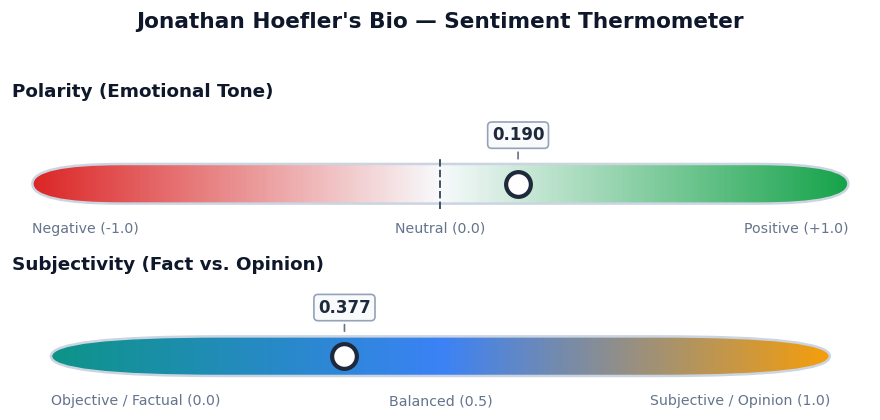

In [102]:
# @title
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='white')

polarity = bio_blob.sentiment.polarity
subjectivity = bio_blob.sentiment.subjectivity

fig, axes = plt.subplots(2, 1, figsize=(7.5, 3.4), dpi=120)
fig.patch.set_facecolor('white')

# Custom color maps using seaborn's blend_palette
polarity_cmap = sns.blend_palette(
    ['#DC2626', '#F8FAFC', '#16A34A'], as_cmap=True
)  # Red -> Neutral -> Green
subjectivity_cmap = sns.blend_palette(
    ['#0D9488', '#3B82F6', '#F59E0B'], as_cmap=True
)  # Teal -> Neutral Blue -> Orange/Yellow


def draw_temp_gauge(
    ax,
    value,
    vmin,
    vmax,
    cmap,
    title,
    left_label,
    mid_label,
    right_label,
    zero_tick=False,
):
  # 1. Create a smooth horizontal color gradient
  gradient = [[i / 255 for i in range(256)]]
  im = ax.imshow(
      gradient,
      aspect='auto',
      cmap=cmap,
      extent=[vmin, vmax, -0.22, 0.22],
      zorder=1,
  )

  # 2. Clip the gradient inside a sleek pill-shaped thermometer tube
  pill = mpatches.FancyBboxPatch(
      (vmin, -0.22),
      vmax - vmin,
      0.44,
      boxstyle='round,pad=0,rounding_size=0.22',
      transform=ax.transData,
  )
  im.set_clip_path(pill)

  # Subtle outer border for the gauge tube
  border = mpatches.FancyBboxPatch(
      (vmin, -0.22),
      vmax - vmin,
      0.44,
      boxstyle='round,pad=0,rounding_size=0.22',
      facecolor='none',
      edgecolor='#CBD5E1',
      linewidth=1.5,
      zorder=2,
  )
  ax.add_patch(border)

  # 3. Optional center neutral line (for Polarity)
  if zero_tick:
    ax.plot(
        [0, 0],
        [-0.28, 0.28],
        color='#475569',
        linestyle='--',
        linewidth=1.2,
        zorder=3,
    )

  # 4. Plot the thermometer "mercury" indicator dot + callout badge
  ax.scatter(
      [value],
      [0],
      s=220,
      color='white',
      edgecolor='#1E293B',
      linewidth=2.5,
      zorder=4,
  )
  ax.annotate(
      f'{value:.3f}',
      xy=(value, 0.24),
      xytext=(value, 0.44),
      ha='center',
      va='bottom',
      fontsize=10,
      fontweight='bold',
      color='#1E293B',
      bbox=dict(
          boxstyle='round,pad=0.25',
          facecolor='#F8FAFC',
          edgecolor='#94A3B8',
          linewidth=1,
      ),
      arrowprops=dict(arrowstyle='-', color='#64748B', lw=1),
      zorder=5,
  )

  # 5. Clean labels and remove axis clutter
  ax.set_xlim(vmin - 0.05, vmax + 0.05)
  ax.set_ylim(-0.55, 0.85)
  ax.set_title(
      title, loc='left', fontsize=11, fontweight='bold', color='#0F172A', pad=6
  )
  ax.text(
      vmin, -0.42, left_label, ha='left', va='top', fontsize=8.5, color='#64748B'
  )
  ax.text(
      (vmin + vmax) / 2,
      -0.42,
      mid_label,
      ha='center',
      va='top',
      fontsize=8.5,
      color='#64748B',
  )
  ax.text(
      vmax,
      -0.42,
      right_label,
      ha='right',
      va='top',
      fontsize=8.5,
      color='#64748B',
  )
  ax.axis('off')


# Top gauge: Polarity (-1.0 Red/Negative -> +1.0 Green/Positive)
draw_temp_gauge(
    axes[0],
    polarity,
    -1.0,
    1.0,
    polarity_cmap,
    'Polarity (Emotional Tone)',
    'Negative (-1.0)',
    'Neutral (0.0)',
    'Positive (+1.0)',
    zero_tick=True,
)

# Bottom gauge: Subjectivity (0.0 Teal/Factual -> 0.5 Neutral Blue -> 1.0 Orange/Yellow)
draw_temp_gauge(
    axes[1],
    subjectivity,
    0.0,
    1.0,
    subjectivity_cmap,
    'Subjectivity (Fact vs. Opinion)',
    'Objective / Factual (0.0)',
    'Balanced (0.5)',
    'Subjective / Opinion (1.0)',
)

fig.suptitle(
    "Jonathan Hoefler's Bio — Sentiment Thermometer",
    fontsize=13,
    fontweight='bold',
    color='#0F172A',
    y=1.02,
)
plt.tight_layout()
plt.show()

# Data Cleaning
Cleaning is painful using .correct

In [103]:
# Turn the Jon's bio into a text blob and correct spelling errors
bio_blob# .correct()

TextBlob("jonathan hoefler born august 22 1970 is an american typeface designer hoefler pronounced heffler founded the hoefler type foundry in 1989 a type foundry in new york in 1999 hoefler began working with type designer tobias frerejones and from 20052014 the company operated under the name hoefler frerejones until their public splithoefler has designed original typefaces for rolling stone magazine harpers bazaar the new york times magazine sports illustrated and esquire and several institutional clients including the solomon r guggenheim museum and alternative band they might be giants perhaps his bestknown work is the hoefler text family of typefaces designed for apple computer and now appearing as part of the macintosh operating system he also designed the current wordmark of the church of the latterday saintsin 1995 hoefler was named one of the forty most influential designers in america by id magazine and in 2002 the association typographique internationale atypi presented him

# Bag of Words Using CountVectorizer

In [104]:
# List all the bios
all_bios[:3]

['digby morrell born 10 october 1979 is a former australian rules footballer who played with the kangaroos and carlton in the australian football league aflfrom western australia morrell played his early senior football for west perth his 44game senior career for the falcons spanned 19982000 and he was the clubs leading goalkicker in 2000 at the age of 21 morrell was recruited to the australian football league by the kangaroos football club with its third round selection in the 2001 afl rookie draft as a forward he twice kicked five goals during his time with the kangaroos the first was in a losing cause against sydney in 2002 and the other the following season in a drawn game against brisbaneafter the 2003 season morrell was traded along with david teague to the carlton football club in exchange for corey mckernan he played 32 games for the blues before being delisted at the end of 2005 he continued to play victorian football league vfl football with the northern bullants carltons vfl

In [105]:
# Perform the count transformation
vectorizer = CountVectorizer(stop_words='english')
bow_vec = vectorizer.fit_transform(all_bios)
print(bow_vec)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 2660 stored elements and shape (20, 2004)>
  Coords	Values
  (0, 611)	1
  (0, 1239)	5
  (0, 310)	1
  (0, 0)	1
  (0, 1304)	1
  (0, 36)	1
  (0, 232)	3
  (0, 1596)	1
  (0, 800)	1
  (0, 1402)	3
  (0, 1051)	3
  (0, 363)	2
  (0, 799)	10
  (0, 1108)	4
  (0, 140)	1
  (0, 1949)	1
  (0, 231)	1
  (0, 654)	1
  (0, 1644)	3
  (0, 1948)	2
  (0, 1378)	1
  (0, 100)	1
  (0, 362)	1
  (0, 750)	1
  (0, 1703)	1
  :	:
  (19, 552)	1
  (19, 691)	1
  (19, 1746)	1
  (19, 983)	1
  (19, 1676)	1
  (19, 1804)	1
  (19, 1494)	1
  (19, 1613)	1
  (19, 583)	1
  (19, 271)	1
  (19, 1899)	1
  (19, 974)	1
  (19, 1896)	1
  (19, 1560)	1
  (19, 1664)	1
  (19, 572)	1
  (19, 987)	1
  (19, 860)	1
  (19, 1090)	1
  (19, 94)	1
  (19, 108)	1
  (19, 5)	1
  (19, 97)	1
  (19, 1650)	1
  (19, 1619)	1


In [106]:
array = bow_vec.toarray()
array

array([[1, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0]], shape=(20, 2004))

In [107]:
doc0_df = pd.DataFrame(array, columns = vectorizer.get_feature_names_out())
doc0_df.shape

(20, 2004)

# TF-IDF

In [108]:
# What is TF-IDF?
f''' {'TF-IDF'} means {'term frequency–inverse document frequency'.title()} '''

' TF-IDF means Term Frequency–Inverse Document Frequency '

## Option 1

In [109]:
# Perform the TF-IDF transformation - Option 1 (TfidfVectorizer)
tf_idf_vec = TfidfVectorizer(stop_words = 'english')
tf_idf = tf_idf_vec.fit_transform(all_bios)
print(tf_idf)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2660 stored elements and shape (20, 2004)>
  Coords	Values
  (0, 611)	0.061319995117112454
  (0, 1239)	0.30659997558556223
  (0, 310)	0.022163279850628746
  (0, 0)	0.04455465584802272
  (0, 1304)	0.053901214305799895
  (0, 36)	0.061319995117112454
  (0, 232)	0.18395998535133737
  (0, 1596)	0.061319995117112454
  (0, 800)	0.061319995117112454
  (0, 1402)	0.14591251665633637
  (0, 1051)	0.18395998535133737
  (0, 363)	0.12263999023422491
  (0, 799)	0.5390121430579989
  (0, 1108)	0.24527998046844982
  (0, 140)	0.061319995117112454
  (0, 1949)	0.061319995117112454
  (0, 231)	0.061319995117112454
  (0, 654)	0.04455465584802272
  (0, 1644)	0.13366396754406815
  (0, 1948)	0.09727501110422425
  (0, 1378)	0.061319995117112454
  (0, 100)	0.061319995117112454
  (0, 362)	0.053901214305799895
  (0, 750)	0.061319995117112454
  (0, 1703)	0.061319995117112454
  :	:
  (19, 552)	0.07687413743897892
  (19, 691)	0.07687413743897892
  (19, 1746)	

In [110]:
array = tf_idf.toarray()

In [111]:
# Print out results in a dataframe
tf_df = pd.DataFrame(array, columns = tf_idf_vec.get_feature_names_out())
tf_df.shape

(20, 2004)

## Option 2

In [112]:
# Perform the TF-IDF transformation - Option 2 (CountVectorizer + TfidfTransformer - better for large datasets)
tf_idf_tran = TfidfTransformer()
tf_idf = tf_idf_tran.fit_transform(bow_vec)
tf_idf

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2660 stored elements and shape (20, 2004)>

In [113]:
# Print out results in a dataframe
tf_df = pd.DataFrame(tf_idf.toarray(), columns = vectorizer.get_feature_names_out())
tf_df.shape

(20, 2004)

In [74]:
# Get a data frame with the TF-IDF values sorted for document 0
doc_df = pd.DataFrame(tf_idf[0].T.todense(), index=tf_idf_vec.get_feature_names_out(), columns=["TF-IDF"])
doc_df = doc_df.sort_values('TF-IDF', ascending=False)
doc_df

,TF-IDF
football,0.539012
morrell,0.306600
league,0.245280
club,0.206094
season,0.183960
...,...
engages,0.000000
engage,0.000000
energy,0.000000
endorsed,0.000000
